# Aryan Dhuru - Homework 5 - Tidy and Process the Billboard Dataset

The goal of this homework is to **tidy** the Billboard dataset and perform some basic analysis and visualization.

You will demonstrate your understanding of data tidying principles and your ability to manipulate and visualize data using Python.



The Billboard dataset comes with **76 columns** corresponding to the chart position of each song from `x1st.week` through `x76th.week`. This is a classic example of **wide** data that needs to be **melted** (unpivoted) into a long (tidy) format.



### Instructions

1. **Project Setup**: Follow the instructions on how to set up your Python and Jupyter (or VSCode) environment, as well as how to clone or download our repository. These can be found in the class notes.

2. **Dataset Path**: Verify the path to the CSV file (e.g. `"../../Datasets/billboard.csv"`). Adjust if necessary.

3. **Load** the Billboard CSV into a DataFrame with `pd.read_csv()`.

4. **Melt/Unpivot** the 76 weekly columns (`x1st.week` through `x76th.week`) into two new columns:

    - `week` (indicating which week of the chart it is, e.g., 1, 2, 3...)

    - `rank` (the song's chart position for that week).

    - This is typically done using `pd.melt()` or `pd.wide_to_long()`.

5. **Clean** the `week` values so that they are numeric (1 to 76) instead of strings like `"x1st.week"`.

6. **Create a `date` column** that indicates the exact date on the chart for each row, using:
   ```
   date = date.entered + (week - 1) * 7 days
   ```
    - You may want to transform `date.entered` in a `datetime` format (you may need to convert it with `pd.to_datetime()` check documentation).

7. **Split** the data into two tables:

    1. **songs** table, which should contain unique song information (e.g., `song_id`, `artist`, `track`, `time`, etc.).

       - Remember to drop duplicates so you only have one row per song.

       - Generate a new `song_id` column that can be used to join back to the weekly info.

    2. **positions** table, which should contain weekly data: `(song_id, week, rank, date)`.

8. **Save** your tidy DataFrames to Feather format:

    - Save the full “tidy” DataFrame (one row per song-week) with a filename suffix `_tidy`.

    - Also save the separate `songs` and `positions` tables as separate Feather files (e.g., `songs.feather`, `positions.feather`).

9. **Submission**:

    - Export your completed notebook to **HTML** or **PDF**.

    - If on Jupyter, select `File` > `Export Notebook As` > `HTML`.

    - If on VSCode, use `Jupyter: Export to HTML` from the command palette.

    - Submit your exported file on Canvas.



 ### Dataset Overview

 The dataset consists of songs and their weekly chart positions on the Billboard Hot 100. It has the following main columns:

 - `year`: The year the song entered the chart.
 - `artist`: The artist of the song.
 - `track`: The title of the song.
 - `time`: The duration of the song.
 - `date.entered`: The date the song first entered the chart.
 - `x1st.week` to `x76th.week`: The chart position of the song for each of the 76 weeks (1 = highest rank, 100 = lower rank).



 ### Goals (Detailed)

 1. **Load** the Billboard dataset from CSV into a pandas DataFrame.

 2. **Tidy** the data by converting the weekly columns into a single `week` column (numeric) and a `rank` column.

 3. **Compute** an exact `date` for each row by adding `(week - 1) * 7 days` to the `date.entered`.

 4. **Split** the data into:

    - **songs**: (One row per song) containing static info and a new `song_id`.

    - **positions**: (One row per song-week) containing columns: `[song_id, week, rank, date]`.

 5. **Save** everything to Feather files (or CSV if you prefer, but Feather is recommended).



 ---

In [134]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
# 1. Load the Billboard dataset
df_bill = pd.read_csv("billboard.csv")  # Adjust path if needed

# Let's quickly check the first few rows to confirm the structure.
df_bill.head()



,year,artist.inverted,track,time,genre,date.entered,date.peaked,x1st.week,x2nd.week,x3rd.week,...,x67th.week,x68th.week,x69th.week,x70th.week,x71st.week,x72nd.week,x73rd.week,x74th.week,x75th.week,x76th.week
0,2000,Destiny's Child,Independent Women Part I,3:38,Rock,2000-09-23,2000-11-18,78,63.0,49.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000,Santana,"Maria, Maria",4:18,Rock,2000-02-12,2000-04-08,15,8.0,6.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2000,Savage Garden,I Knew I Loved You,4:07,Rock,1999-10-23,2000-01-29,71,48.0,43.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2000,Madonna,Music,3:45,Rock,2000-08-12,2000-09-16,41,23.0,18.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2000,"Aguilera, Christina",Come On Over Baby (All I Want Is You),3:38,Rock,2000-08-05,2000-10-14,57,47.0,45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


  The dataset has columns like:



  - **year**, **artist.inverted**, **track**, **time**, **genre**, etc. (Song info)

  - **date.entered**, **date.peaked** (Chart-related dates)

  - **x1st.week** through **x76th.week** (Chart positions over 76 weeks)



  Our objective is to **melt** these weekly columns into a single `week` and `rank` column.

In [137]:
# 2. Melt/unpivot the data into a "tidy" format.
# HINT: you can use pd.melt(). 
# We'll create a new DataFrame, for example df_tidy.

# Your code here
suffix = lambda n: 'th' if 11<=n<=13 else {1:'st', 2:'nd', 3:'rd'}.get(n % 10, 'th')
value_vars = [f"x{week}{suffix(week)}.week" for week in range(1, 77)]

df_tidy = pd.melt(df_bill, id_vars=df_bill.columns[:df_bill.columns.get_loc('x1st.week')],
                  value_vars=value_vars,
                  var_name='week', value_name='rank')



  After melting, each row should represent **one song** in **one week**. However, the `week` column will have strings like `"x1st.week"`, `"x2nd.week"`, etc. Let's clean those up and create a numeric week column.

In [140]:
# 3. Convert the week column to numeric (strip the "x", remove ".week", etc.)

# Your code here

df_tidy['week'] = df_tidy['week'].str.extract(r'(\d+)').astype(int)
df_tidy.head()


,year,artist.inverted,track,time,genre,date.entered,date.peaked,week,rank
0,2000,Destiny's Child,Independent Women Part I,3:38,Rock,2000-09-23,2000-11-18,1,78.0
1,2000,Santana,"Maria, Maria",4:18,Rock,2000-02-12,2000-04-08,1,15.0
2,2000,Savage Garden,I Knew I Loved You,4:07,Rock,1999-10-23,2000-01-29,1,71.0
3,2000,Madonna,Music,3:45,Rock,2000-08-12,2000-09-16,1,41.0
4,2000,"Aguilera, Christina",Come On Over Baby (All I Want Is You),3:38,Rock,2000-08-05,2000-10-14,1,57.0


  Now, `week` should be 1, 2, 3, ... 76. Next, we want to calculate the **exact date** on the chart for each row by adding `(week - 1) * 7 days` to `date.entered`. Create a column named `"date"` to hold the result. Make sure `date.entered` is converted to datetime first, if it isn't already.

In [143]:
# 4. Create the 'date' column: date = date.entered + (week - 1)*7 days

# Your code here
df_tidy['date.entered'] = pd.to_datetime(df_tidy['date.entered'])

df_tidy['date'] = df_tidy['date.entered'] + pd.to_timedelta((df_tidy['week'] - 1) * 7, unit='days')

df_tidy.head()

,year,artist.inverted,track,time,genre,date.entered,date.peaked,week,rank,date
0,2000,Destiny's Child,Independent Women Part I,3:38,Rock,2000-09-23,2000-11-18,1,78.0,2000-09-23
1,2000,Santana,"Maria, Maria",4:18,Rock,2000-02-12,2000-04-08,1,15.0,2000-02-12
2,2000,Savage Garden,I Knew I Loved You,4:07,Rock,1999-10-23,2000-01-29,1,71.0,1999-10-23
3,2000,Madonna,Music,3:45,Rock,2000-08-12,2000-09-16,1,41.0,2000-08-12
4,2000,"Aguilera, Christina",Come On Over Baby (All I Want Is You),3:38,Rock,2000-08-05,2000-10-14,1,57.0,2000-08-05


  ### 5. Split into Two Tables

  **Why split?** We often separate the **static** song info (e.g., artist, track, time, genre) from the **weekly** chart performance (week, rank, date).

  - **Songs Table**: Contains unique identifiers for each song plus basic metadata.

  - **Positions Table**: Contains `(song_id, week, rank, date)`, referencing the **song_id** from the songs table.



  Generate a new `song_id` for each unique song, then merge/join this `song_id` back into the melted DataFrame.

In [148]:
# 5.1 Create a songs table (unique rows). Assign a song_id. 
# Then merge that ID back into the main tidy DataFrame.

songs = df_tidy.drop_duplicates(subset=['artist.inverted', 'track']).copy()
songs['song_id'] = range(1, len(songs) + 1)
songs = songs[['song_id', 'artist.inverted', 'track', 'time', 'year']]
songs.rename(columns={'artist.inverted': 'artist'}, inplace=True)

print("Songs Table:")
print(songs.head())

Songs Table:
   song_id               artist                                  track  time  \
0        1      Destiny's Child               Independent Women Part I  3:38   
1        2              Santana                           Maria, Maria  4:18   
2        3        Savage Garden                     I Knew I Loved You  4:07   
3        4              Madonna                                  Music  3:45   
4        5  Aguilera, Christina  Come On Over Baby (All I Want Is You)  3:38   

   year  
0  2000  
1  2000  
2  2000  
3  2000  
4  2000  


  ### 6. Create the Positions Table

  Once the `song_id` is part of the melted DataFrame, we can select the columns `(song_id, week, rank, date)` into a separate DataFrame called **positions**.

In [150]:
# Your code here
positions = pd.merge(df_tidy, songs[['song_id', 'artist', 'track']],
                     left_on=['artist.inverted', 'track'], right_on=['artist', 'track'], how='left')
positions = positions[['song_id', 'week', 'rank', 'date']]

print("Positions Table:")
print(positions.head())

Positions Table:
   song_id  week  rank       date
0        1     1  78.0 2000-09-23
1        2     1  15.0 2000-02-12
2        3     1  71.0 1999-10-23
3        4     1  41.0 2000-08-12
4        5     1  57.0 2000-08-05


 By the end of this process you should have:

 - A **songs** table with unique song info and a `song_id` for each song (keep song names, artists, etc.)

 - A **positions** table with `(song_id, week, rank, date)` for each song-week.

 For example:

 songs table:

 | song_id | artist         | track          | time  | year |
 |---------|----------------|----------------|-------|------|
 | 1       | The Beatles    | Hey Jude       | 3:35  | 1968 |
 | 2       | Elton John     | Rocket         | 3:10  | 1972 |
 | 3       | Whitney Houston | I Will Always  | 4:30  | 1992 |
 | ...     | ...            | ...            | ...   | ...  |


 positions table:

 | song_id | week | rank | date       |
 |---------|------|------|------------|
 | 1       | 1    | 1    | 1968-09-14 |
 | 1       | 2    | 1    | 1968-09-21 |
 | 1       | 3    | 1    | 1968-09-28 |
 | ...     | ...  | ...  | ...        |



  ### 7. Save Tidy Data to Feather

  We want to save:

  - The **complete tidy** DataFrame (one row per song-week) with a filename suffix `_tidy`.

  - The **songs** and **positions** tables as separate Feather files.



In [152]:
# Your code here

df_tidy.reset_index(drop=True).to_feather('df_tidy.feather')  # Reset index to ensure clean saving
songs.reset_index(drop=True).to_feather('songs_table.feather')  # Reset index for clean format
positions.reset_index(drop=True).to_feather('positions_table.feather')  # Reset index for clean format

print("Data has been saved to Feather format.")

Data has been saved to Feather format.


## Part 1 - Basic Analysis



 Below are some guided analyses to help you get started. Feel free to explore more on your own!



 ### A. Only songs that reached top 10

 1. Use `query()` to filter rows in `positions` for `rank <= 10`.

 2. Merge or join with the `songs` table to get the song details.



 **Hint**: Remember you can drop duplicates if you only want the list of unique songs that reached top 10.

In [170]:
#your code here

top_10_positions = positions.query('rank <= 10')
unique_top_10_songs = top_10_song_details.drop_duplicates(subset=['song_id'])

print("Songs that Reached Top 10:")
print(unique_top_10_songs[['artist', 'track', 'time', 'year']].drop_duplicates())
total_unique_songs = unique_top_10_songs['song_id'].nunique()
print("Total number of unique songs that reached the top 10:", total_unique_songs)

Songs that Reached Top 10:
                          artist                                  track  time  \
0                Destiny's Child               Independent Women Part I  3:38   
1                        Santana                           Maria, Maria  4:18   
2                  Savage Garden                     I Knew I Loved You  4:07   
3                        Madonna                                  Music  3:45   
4            Aguilera, Christina  Come On Over Baby (All I Want Is You)  3:38   
5                          Janet                  Doesn't Really Matter  4:17   
6                Destiny's Child                            Say My Name  4:31   
7              Iglesias, Enrique                            Be With You  3:36   
8                          Sisqo                             Incomplete  3:52   
9                       Lonestar                                 Amazed  4:25   
10                        N'Sync                       It's Gonna Be Me  3:10   
1

 ### B. How long did each song stay in the top 10?



 1. Filter `positions` for `rank <= 10`.

 2. Group by `song_id` and count the number of rows. This gives `weeks_in_top_10`.

 3. Merge back with the `songs` table to display the track/artist.

In [166]:
# Your code here
weeks_in_top_10 = top_10_positions.groupby('song_id').size().reset_index(name='weeks_in_top_10')
top_10_song_details = pd.merge(weeks_in_top_10, songs, on='song_id', how='left')
print("Songs and their weeks in Top 10:")
print(top_10_song_details[['artist', 'track', 'weeks_in_top_10']])


Songs and their weeks in Top 10:
                          artist                                  track  \
0                Destiny's Child               Independent Women Part I   
1                        Santana                           Maria, Maria   
2                  Savage Garden                     I Knew I Loved You   
3                        Madonna                                  Music   
4            Aguilera, Christina  Come On Over Baby (All I Want Is You)   
5                          Janet                  Doesn't Really Matter   
6                Destiny's Child                            Say My Name   
7              Iglesias, Enrique                            Be With You   
8                          Sisqo                             Incomplete   
9                       Lonestar                                 Amazed   
10                        N'Sync                       It's Gonna Be Me   
11           Aguilera, Christina                      What A Girl W

 ### C. In which week did each song *first* reach the top 10?



 1. Again filter for `rank <= 10`.

 2. Group by `song_id` and find the minimum `week` value. Call this `week_reached_top_10`.

In [ ]:
# Your code here
first_top_10_week = top_10_positions.groupby('song_id')['week'].min().reset_index()
first_top_10_week.rename(columns={'week': 'week_reached_top_10'}, inplace=True)
songs_first_top_10 = pd.merge(first_top_10_week, songs, on='song_id', how='left')
print("Week Each Song First Reached Top 10:")
print(songs_first_top_10[['artist', 'track', 'week_reached_top_10']])

Week Each Song First Reached Top 10:
                          artist                                  track  \
0                Destiny's Child               Independent Women Part I   
1                        Santana                           Maria, Maria   
2                  Savage Garden                     I Knew I Loved You   
3                        Madonna                                  Music   
4            Aguilera, Christina  Come On Over Baby (All I Want Is You)   
5                          Janet                  Doesn't Really Matter   
6                Destiny's Child                            Say My Name   
7              Iglesias, Enrique                            Be With You   
8                          Sisqo                             Incomplete   
9                       Lonestar                                 Amazed   
10                        N'Sync                       It's Gonna Be Me   
11           Aguilera, Christina                      What A Gi



 ## Part 2 - Visualization



 For this part, you may use **Altair** (*Preferable!*), **Matplotlib**, **Seaborn**, or any other Python visualization library.



 Below are some suggested questions and plots:



 1. **Histogram of Weeks in the Top 10**

    - How many songs stayed for 1 week vs. 2 weeks vs. 10 weeks in the top 10?

    - Plot this distribution.

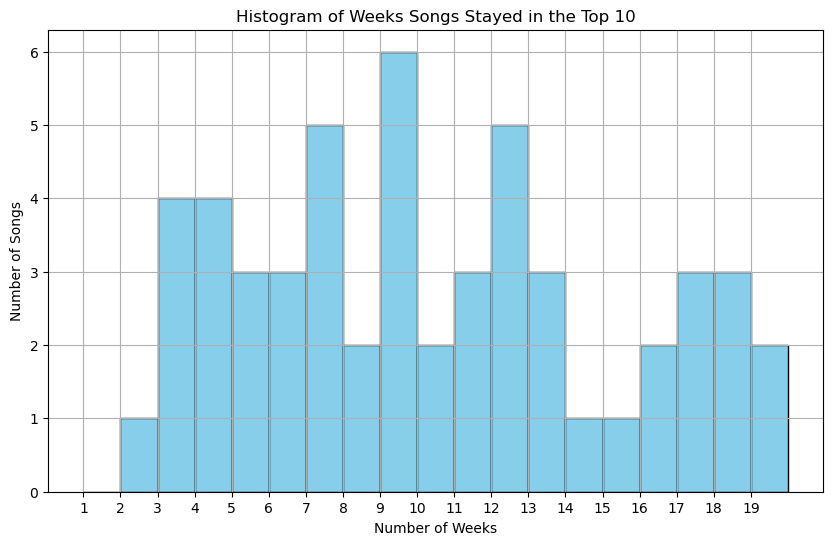

In [160]:
# 1. Example: Histogram of the number of weeks each song stayed in the top 10.
# (Assuming you've created a 'weeks_in_top_10' table or series.)

# Your code here
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(top_10_song_details['weeks_in_top_10'], bins=range(1, top_10_song_details['weeks_in_top_10'].max() + 2), color='skyblue', edgecolor='black')
plt.title('Histogram of Weeks Songs Stayed in the Top 10')
plt.xlabel('Number of Weeks')
plt.ylabel('Number of Songs')
plt.xticks(range(1, top_10_song_details['weeks_in_top_10'].max() + 1))
plt.grid(True)
plt.show()




 2. **Line Chart of a Song's Rank Over Time**

    - Pick a well-known song from the dataset (e.g., one of the most weeks at #1).

    - Plot its `rank` vs. `date` (or `week`).

    - The line should show how the rank changes over consecutive weeks.

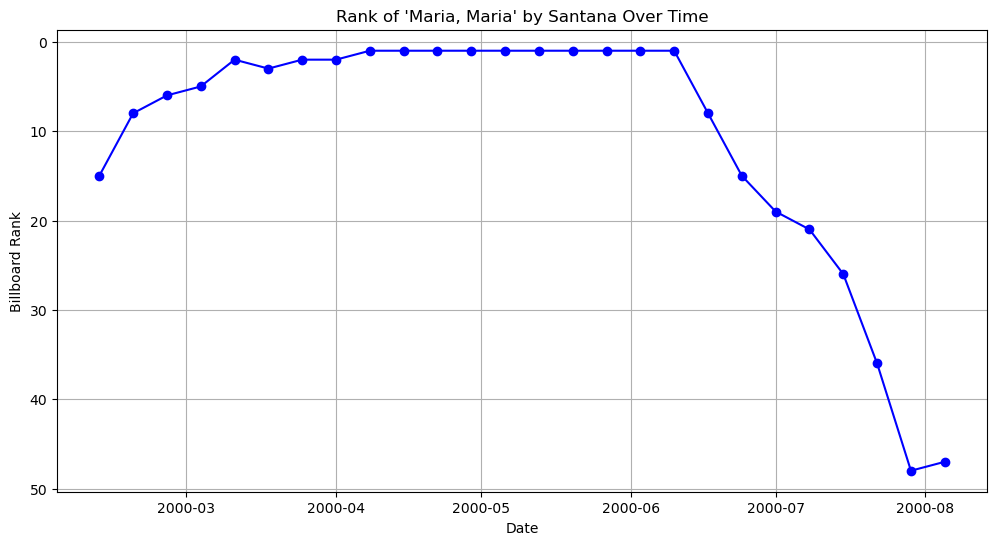

In [164]:
# Use the original `positions` DataFrame to plot a song's rank over time.
# Your code here

positions_with_details = pd.merge(positions, songs[['song_id', 'artist', 'track']], on='song_id', how='left')
song_title = "Maria, Maria"  
song_artist = "Santana"  

song_data = positions_with_details[(positions_with_details['track'] == song_title) & 
                                   (positions_with_details['artist'] == song_artist)]

song_data = song_data.sort_values('date')


plt.figure(figsize=(12, 6))
plt.plot(song_data['date'], song_data['rank'], marker='o', linestyle='-', color='b')
plt.title(f"Rank of '{song_title}' by {song_artist} Over Time")
plt.xlabel('Date')
plt.ylabel('Billboard Rank')
plt.gca().invert_yaxis()  
plt.grid(True)
plt.show()

 3. **Distribution of Peak Ranks**

    - For each song, find its **best** (lowest number) rank.

    - Plot a histogram of these peak positions. Where do most songs peak? (#1, #5, #20, etc.)

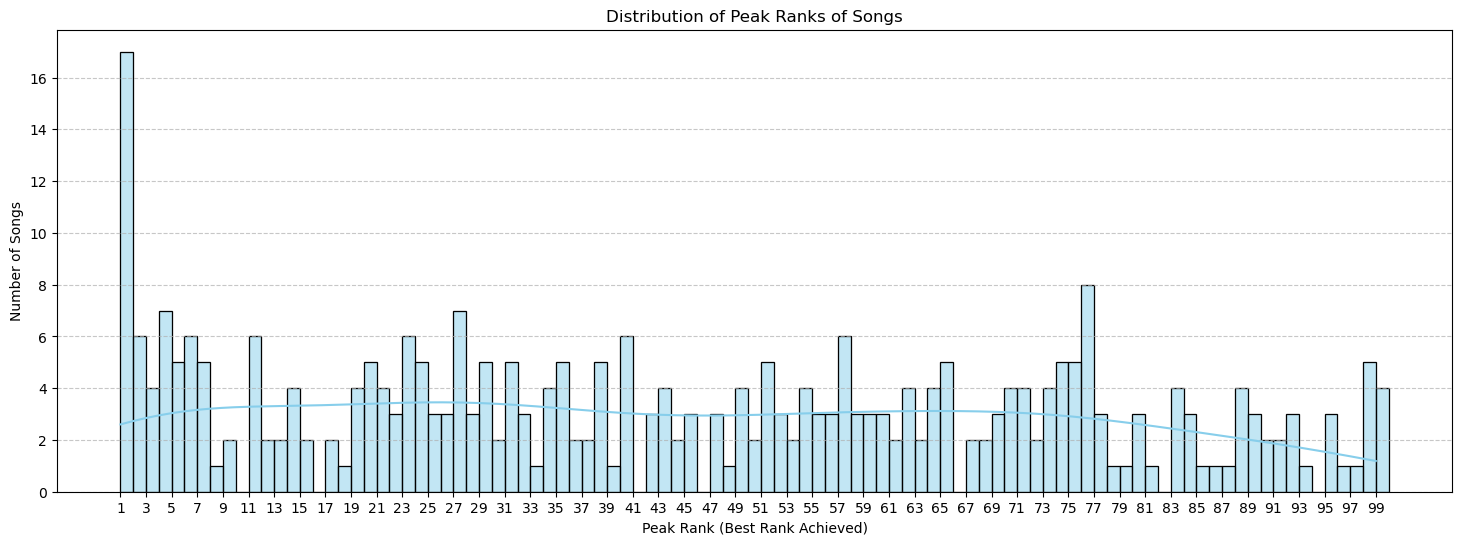

In [ ]:
# Your code here


peak_ranks = positions.groupby('song_id')['rank'].min().reset_index()
peak_ranks.rename(columns={'rank': 'peak_rank'}, inplace=True)

peak_ranks = pd.merge(peak_ranks, songs[['song_id', 'artist', 'track']], on='song_id', how='left')

peak_ranks['peak_rank'] = peak_ranks['peak_rank'].astype(int)

plt.figure(figsize=(18, 6)) 
sns.histplot(peak_ranks['peak_rank'], bins=range(1, int(peak_ranks['peak_rank'].max()) + 2), kde=True, color="skyblue")

plt.title('Distribution of Peak Ranks of Songs')
plt.xlabel('Peak Rank (Best Rank Achieved)')
plt.ylabel('Number of Songs')
plt.xticks(range(1, int(peak_ranks['peak_rank'].max()) + 1, 2), rotation=0)  # Show every 2nd label horizontally
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()




 ## Bonus: Additional Analysis (Optional, but will give you extra credit!)

 *(Add more charts and visualizations as you see fit!)*

 Be creative and explore the dataset! showcase at least a new plot or analysis.

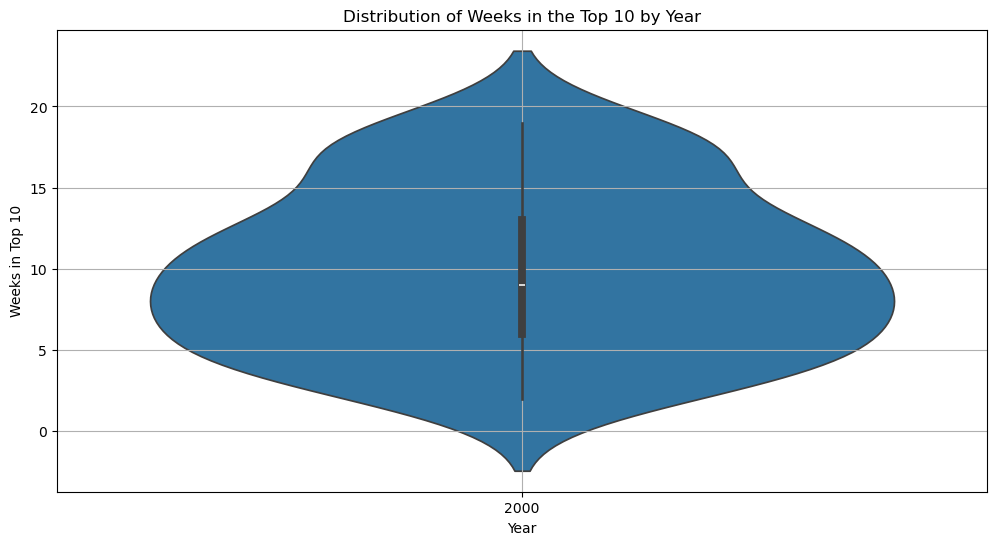

In [ ]:
# Your extra analyses here

import seaborn as sns
plt.figure(figsize=(12, 6))
sns.violinplot(x='year', y='weeks_in_top_10', data=top_10_song_details)
plt.title('Distribution of Weeks in the Top 10 by Year')
plt.xlabel('Year')
plt.ylabel('Weeks in Top 10')
plt.grid(True)
plt.show()


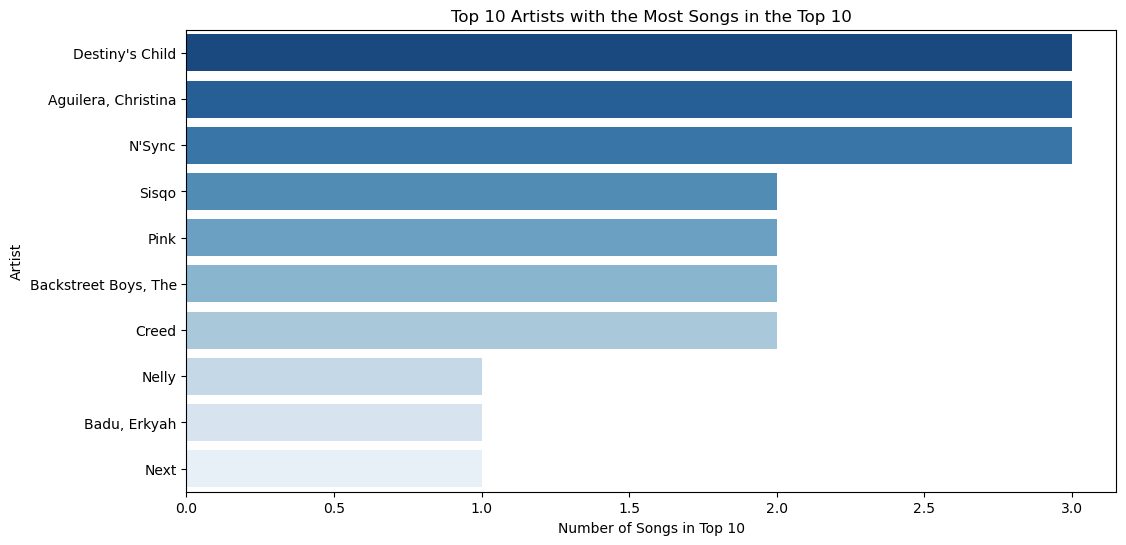

In [126]:
top_artists = top_10_song_details['artist'].value_counts().head(10)  

plt.figure(figsize=(12, 6))
sns.barplot(x=top_artists.values, y=top_artists.index, palette="Blues_r")
plt.title("Top 10 Artists with the Most Songs in the Top 10")
plt.xlabel("Number of Songs in Top 10")
plt.ylabel("Artist")
plt.show()




 ### Final Instructions

 1. Make sure your notebook runs from top to bottom without errors.

 2. Export it to HTML or PDF.

 3. Submit via Canvas.



 Good luck and have fun exploring the Billboard dataset!